# Chapter 2. What do we know, and when?

*Input, target, prediction time; the repeat-purchase target.*

Marketing wants a score per member for "will buy again in the next ninety days". Before any model, three things must be pinned down: the moment the score is made (the prediction time), what the model may read at that moment (the input), and what it is scored against afterwards (the target). This chapter builds all three on eight orders from four invented Kalpa members.

By the end you can define the ninety-day repeat flag from an order log with a cutoff date, build features that use only what was known at the cutoff, and spot the version that quietly reads the future.

**Search terms:** features and labels, supervised learning setup, prediction time, label leakage, target definition.

In [1]:
# Tools for this notebook, and one helper that prints a check as PASS or FAIL.
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

def check(label, ok):
    print(("PASS  " if ok else "FAIL  ") + label)

print("ready: pandas", pd.__version__, "and matplotlib", plt.matplotlib.__version__)

ready: pandas 3.0.5 and matplotlib 3.11.2


In [2]:
# Eight orders from four Kalpa members, invented for teaching.
orders = pd.DataFrame({
    "member": ["M1", "M1", "M2", "M2", "M2", "M3", "M4", "M4"],
    "order_date": pd.to_datetime(["2026-04-10", "2026-07-20", "2026-05-02", "2026-06-15", "2026-06-28",
                                  "2026-06-01", "2026-04-25", "2026-10-15"]),
    "amount_rs": [800, 650, 400, 1200, 300, 950, 500, 700],
})
CUTOFF = pd.Timestamp("2026-06-30")
WINDOW_END = CUTOFF + pd.Timedelta(days=90)
print(orders.to_string(index=False))
print(f"\nprediction time (the cutoff): {CUTOFF.date()}; the outcome window runs to {WINDOW_END.date()}")

member order_date  amount_rs
    M1 2026-04-10        800
    M1 2026-07-20        650
    M2 2026-05-02        400
    M2 2026-06-15       1200
    M2 2026-06-28        300
    M3 2026-06-01        950
    M4 2026-04-25        500
    M4 2026-10-15        700

prediction time (the cutoff): 2026-06-30; the outcome window runs to 2026-09-28


## Where does each order sit against the cutoff?

The prediction is made on 30 June. An order on or before that date is history the model may read. An order in the ninety days after it decides the target. An order after the window counts for neither.

**Predict before you run.** How many of the four members buy again inside the window? (a) none (b) one (c) two (d) four

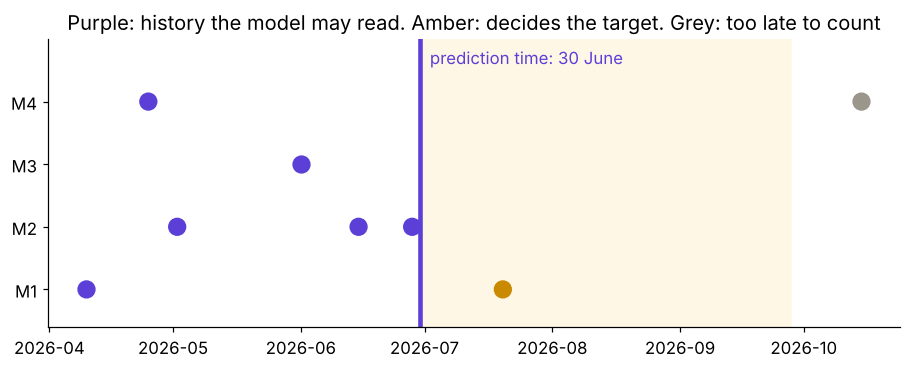

In [3]:
# The week's timeline picture on four members: history, the cutoff, the outcome window.
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.axvspan(CUTOFF, WINDOW_END, color="#FFF7E6", label="outcome window, 90 days")
ax.axvline(CUTOFF, color="#5B3FD6", lw=3)
for i, m in enumerate(["M1", "M2", "M3", "M4"]):
    d = orders[orders["member"] == m]
    colours = ["#5B3FD6" if t <= CUTOFF else ("#C98A00" if t <= WINDOW_END else "#9A968C") for t in d["order_date"]]
    ax.scatter(d["order_date"], [i] * len(d), s=120, c=colours, zorder=3)
ax.set_yticks(range(4)); ax.set_yticklabels(["M1", "M2", "M3", "M4"])
ax.text(CUTOFF, 3.6, "  prediction time: 30 June", color="#5B3FD6", fontsize=11)
ax.set_ylim(-0.6, 4.0); ax.set_title("Purple: history the model may read. Amber: decides the target. Grey: too late to count")
plt.show()

In [4]:
# Inputs: only orders on or before the cutoff. Target: any order in the 90 days after it.
history = orders[orders["order_date"] <= CUTOFF]
window = orders[(orders["order_date"] > CUTOFF) & (orders["order_date"] <= WINDOW_END)]
table = pd.DataFrame({"member": ["M1", "M2", "M3", "M4"]}).set_index("member")
table["orders_before"] = history.groupby("member").size()
table["days_since_last"] = (CUTOFF - history.groupby("member")["order_date"].max()).dt.days
table["spend_before_rs"] = history.groupby("member")["amount_rs"].sum()
table["repeat_90d"] = table.index.isin(window["member"]).astype(int)
table = table.fillna(0).astype(int)
print(table.to_string())
check("no input uses an order dated after the cutoff", history["order_date"].max() <= CUTOFF)
check("the target window is exactly 90 days", (WINDOW_END - CUTOFF).days == 90)

        orders_before  days_since_last  spend_before_rs  repeat_90d
member                                                             
M1                  1               81              800           1
M2                  3                2             1900           0
M3                  1               29              950           0
M4                  1               66              500           0
PASS  no input uses an order dated after the cutoff
PASS  the target window is exactly 90 days


**What happened.** The answer is (b): only M1 buys inside the window (20 July). M4's next order, on 15 October, falls after the window closes, so M4's target is 0 even though M4 did buy again. The target is a definition, and "buy again" means "inside these ninety days" because that is what Marketing's budget covers.

## The trap: features computed on the whole log

A hurried analyst counts each member's orders on the full table, because that is the table they have today.

In [5]:
# The leaky version: count orders on the full log, which includes the window itself.
leaky = table.copy()
leaky["orders_all_time"] = orders.groupby("member").size()
print(leaky[["orders_before", "orders_all_time", "repeat_90d"]].to_string())
print("\nM1 shows 2 orders all-time: one of them is the very purchase the model is meant to predict.")
check("the leaky count is larger exactly where the target or a later order sits", (leaky["orders_all_time"] > leaky["orders_before"]).sum() == 2)

        orders_before  orders_all_time  repeat_90d
member                                            
M1                  1                2           1
M2                  3                3           0
M3                  1                1           0
M4                  1                2           0

M1 shows 2 orders all-time: one of them is the very purchase the model is meant to predict.
PASS  the leaky count is larger exactly where the target or a later order sits


**Why it is wrong in Kalpa's terms.** On the day of the nudge, Marketing does not know about the 20 July order. A feature that counts it hands the model the answer, so the score looks brilliant offline and collapses the first morning it runs on real members. **The check:** for every input column, ask "would I know this value on 30 June?" **The fix:** compute every input from orders dated on or before the cutoff, and the target only from the window.

## What did this chapter establish?

| Question | Answer |
|---|---|
| What is the prediction time? | the cutoff, 30 June: the morning Marketing sends the nudge |
| What is the input? | anything known on or before the cutoff: orders, recency, spend |
| What is the target? | at least one order in the 90 days after the cutoff, 1 for M1 only |
| What breaks if the log is read whole? | inputs count the target's own purchase, and the offline score lies |

**Interview line:** "I fix the prediction time first, build every input from data dated on or before it, and define the target only from the window after it; a frozen reference date is what keeps the label honest."